In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [8]:
from google.colab import files

uploaded = files.upload()

Saving raw_sensor.csv to raw_sensor (1).csv


In [9]:
df = pd.read_csv("raw_sensor.csv")

print("Data loaded successfully.")

Data loaded successfully.


In [10]:
df.head()

,Raw_Temperature_C,Calibrated_Temperature_C,Humidity_Percent,LDR_Analog_Value,Motion_Detected
0,31.1,28.0,49.9,1600,No
1,31.1,28.0,50.0,1591,No
2,31.1,28.0,50.0,1589,No
3,31.1,28.0,50.1,1584,No
4,31.1,28.0,50.1,1607,No


In [11]:
# Display the last five records

df.tail()

,Raw_Temperature_C,Calibrated_Temperature_C,Humidity_Percent,LDR_Analog_Value,Motion_Detected
2072,31.3,28.1,49.7,1776,Yes
2073,31.2,28.1,49.4,1751,Yes
2074,31.3,28.1,49.4,1714,Yes
2075,31.3,28.1,49.5,1712,No
2076,31.2,28.1,49.6,1687,No


In [12]:
# STEP 4: Dataset dimensions

print("Number of observations:", df.shape[0])
print("Number of variables:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Number of observations: 2077
Number of variables: 5

Column names:
['Raw_Temperature_C', 'Calibrated_Temperature_C', 'Humidity_Percent', 'LDR_Analog_Value', 'Motion_Detected']

Data types:
Raw_Temperature_C           float64
Calibrated_Temperature_C    float64
Humidity_Percent            float64
LDR_Analog_Value              int64
Motion_Detected              object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2077 entries, 0 to 2076
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Raw_Temperature_C         2077 non-null   float64
 1   Calibrated_Temperature_C  2077 non-null   float64
 2   Humidity_Percent          2077 non-null   float64
 3   LDR_Analog_Value          2077 non-null   int64  
 4   Motion_Detected           2077 non-null   object 
dtypes: float64(3), int64(1), object(1)
memory usage: 81.3+ KB


In [13]:
# STEP 6: Convert sensor readings into numeric values

numeric_columns = [
    'Raw_Temperature_C',
    'Calibrated_Temperature_C',
    'Humidity_Percent',
    'LDR_Analog_Value'
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')

# Identify invalid readings
invalid_temperature = (
    (df['Raw_Temperature_C'] < -40) |
    (df['Raw_Temperature_C'] > 125)
)

invalid_humidity = (
    (df['Humidity_Percent'] < 0) |
    (df['Humidity_Percent'] > 100)
)

invalid_light = (
    (df['LDR_Analog_Value'] < 0) |
    (df['LDR_Analog_Value'] > 4095)
)

print("Invalid temperature readings:", invalid_temperature.sum())
print("Invalid humidity readings:", invalid_humidity.sum())
print("Invalid light readings:", invalid_light.sum())

Invalid temperature readings: 0
Invalid humidity readings: 0
Invalid light readings: 0


In [14]:
# STEP 7: Create sample number and elapsed time

df['Sample_Number'] = range(1, len(df) + 1)

df['Elapsed_Time_Seconds'] = df['Sample_Number'] - 1

print("Time columns created successfully!")

df[['Sample_Number', 'Elapsed_Time_Seconds']].head()

Time columns created successfully!


,Sample_Number,Elapsed_Time_Seconds
0,1,0
1,2,1
2,3,2
3,4,3
4,5,4


In [15]:
# STEP 8: Descriptive statistics

sensor_columns = [
    'Raw_Temperature_C',
    'Calibrated_Temperature_C',
    'Humidity_Percent',
    'LDR_Analog_Value'
]

statistics = df[sensor_columns].describe().T

statistics = statistics[['mean', 'min', 'max', 'std']]

print("DESCRIPTIVE STATISTICS")

display(statistics)

DESCRIPTIVE STATISTICS


,mean,min,max,std
Raw_Temperature_C,32.027251,31.1,35.1,0.740299
Calibrated_Temperature_C,28.874145,28.0,32.0,0.747263
Humidity_Percent,48.672701,45.2,73.5,3.527346
LDR_Analog_Value,1874.549831,241.0,4095.0,782.974937


In [16]:
# STEP 9: Calculate sensor variability

variability = df[sensor_columns].std()

print("Sensor variability:")

display(variability.sort_values(ascending=False))

print("Sensor with greatest variability:")
print(variability.idxmax())

Sensor variability:


,0
LDR_Analog_Value,782.974937
Humidity_Percent,3.527346
Calibrated_Temperature_C,0.747263
Raw_Temperature_C,0.740299


Sensor with greatest variability:
LDR_Analog_Value


In [17]:
# STEP 10: Temperature calibration analysis

reference_temperature = 28.0
calibration_offset = -2.03

raw_mean = df['Raw_Temperature_C'].mean()

calibrated_mean = df['Calibrated_Temperature_C'].mean()

raw_error = abs(raw_mean - reference_temperature)

calibrated_error = abs(calibrated_mean - reference_temperature)

print("Reference temperature:", reference_temperature, "°C")

print("Average raw temperature:", round(raw_mean, 2), "°C")

print("Average calibrated temperature:",
      round(calibrated_mean, 2), "°C")

print("\nError before calibration:",
      round(raw_error, 2), "°C")

print("Error after calibration:",
      round(calibrated_error, 2), "°C")

print("Calibration offset:", calibration_offset, "°C")

Reference temperature: 28.0 °C
Average raw temperature: 32.03 °C
Average calibrated temperature: 28.87 °C

Error before calibration: 4.03 °C
Error after calibration: 0.87 °C
Calibration offset: -2.03 °C


In [18]:
# STEP 11: Apply five-sample moving average

df['Filtered_Temperature_C'] = (
    df['Calibrated_Temperature_C']
    .rolling(window=5, min_periods=1)
    .mean()
)

print("Moving average filter applied!")

display(df[[
    'Calibrated_Temperature_C',
    'Filtered_Temperature_C'
]].head(10))

Moving average filter applied!


,Calibrated_Temperature_C,Filtered_Temperature_C
0,28.0,28.0
1,28.0,28.0
2,28.0,28.0
3,28.0,28.0
4,28.0,28.0
5,28.0,28.0
6,28.0,28.0
7,28.0,28.0
8,28.0,28.0
9,28.0,28.0


In [19]:
# STEP 12: Calculate temperature rate of change

df['Temperature_Rate_of_Change'] = (
    df['Calibrated_Temperature_C'].diff()
)

print("Rate of change calculated!")

display(df[[
    'Calibrated_Temperature_C',
    'Temperature_Rate_of_Change'
]].head(10))

Rate of change calculated!


,Calibrated_Temperature_C,Temperature_Rate_of_Change
0,28.0,NaN
1,28.0,0.0
2,28.0,0.0
3,28.0,0.0
4,28.0,0.0
5,28.0,0.0
6,28.0,0.0
7,28.0,0.0
8,28.0,0.0
9,28.0,0.0


In [20]:
# STEP 13: Convert motion readings into numerical values

df['Motion_Detected'] = (
    df['Motion_Detected']
    .astype(str)
    .str.strip()
    .str.lower()
    .map({
        'yes': 1,
        'no': 0
    })
)

print("Motion readings converted successfully!")

print("\nMotion reading distribution:")

display(df['Motion_Detected'].value_counts())

Motion readings converted successfully!

Motion reading distribution:


,count
Motion_Detected,
0,1299
1,778


In [21]:
# Count positive motion readings

motion_readings = df['Motion_Detected'].sum()

# Count transitions from No Motion to Motion
motion_events = (
    df['Motion_Detected'].diff().eq(1).sum()
)

print("Motion-positive readings:", int(motion_readings))

print("Detected motion events:", int(motion_events))

Motion-positive readings: 778
Detected motion events: 249


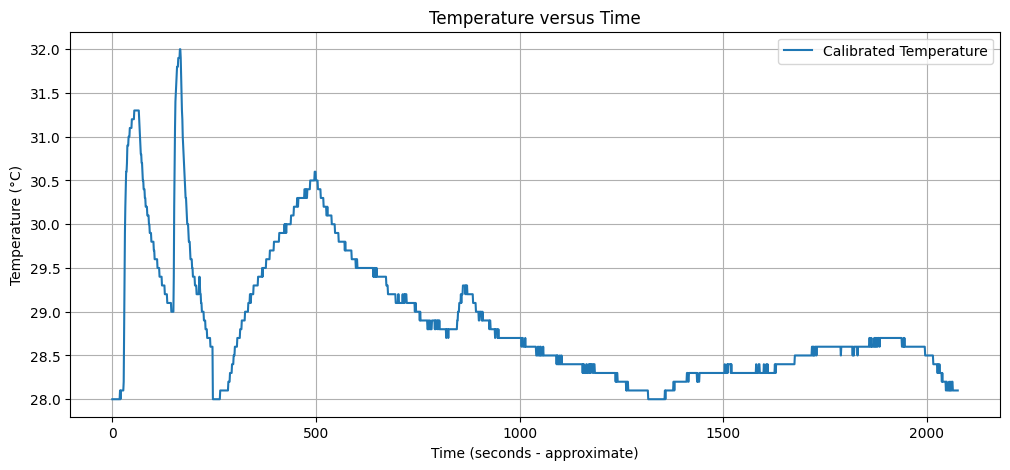

In [25]:
# GRAPH 1: Temperature versus Time

plt.figure(figsize=(12, 5))

plt.plot(
    df['Elapsed_Time_Seconds'],
    df['Calibrated_Temperature_C'],
    label='Calibrated Temperature'
)

plt.xlabel('Time (seconds - approximate)')
plt.ylabel('Temperature (°C)')
plt.title('Temperature versus Time')

plt.legend()
plt.grid(True)


plt.show()

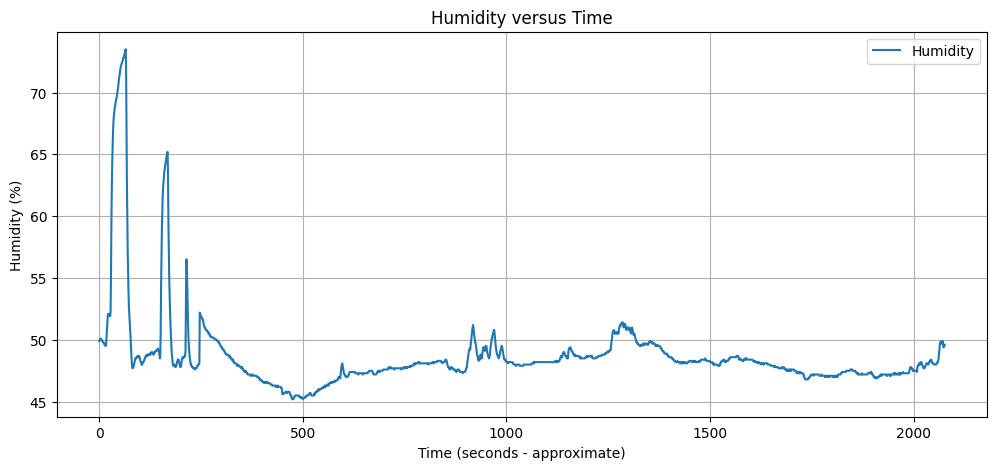

In [26]:
# GRAPH 2: Humidity versus Time

plt.figure(figsize=(12, 5))

plt.plot(
    df['Elapsed_Time_Seconds'],
    df['Humidity_Percent'],
    label='Humidity'
)

plt.xlabel('Time (seconds - approximate)')
plt.ylabel('Humidity (%)')
plt.title('Humidity versus Time')

plt.legend()
plt.grid(True)



plt.show()

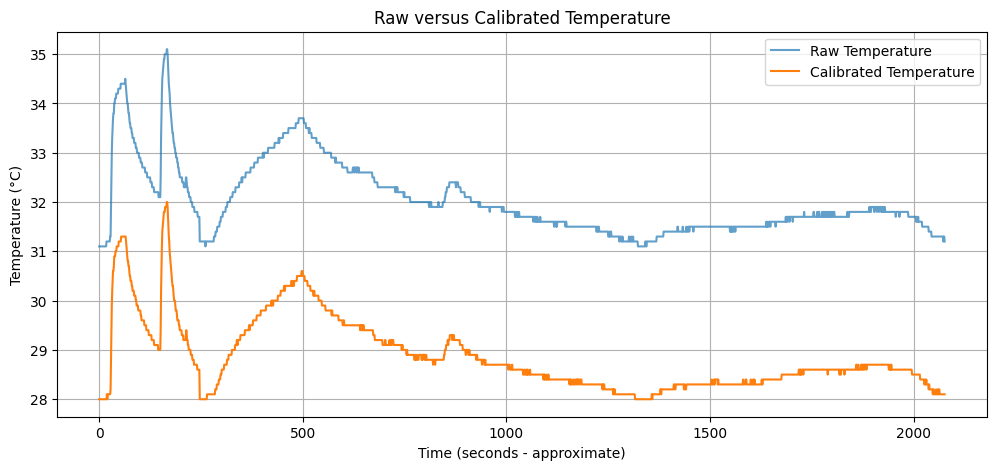

In [27]:
# GRAPH 3: Raw versus Calibrated Temperature

plt.figure(figsize=(12, 5))

plt.plot(
    df['Elapsed_Time_Seconds'],
    df['Raw_Temperature_C'],
    label='Raw Temperature',
    alpha=0.7
)

plt.plot(
    df['Elapsed_Time_Seconds'],
    df['Calibrated_Temperature_C'],
    label='Calibrated Temperature'
)

plt.xlabel('Time (seconds - approximate)')
plt.ylabel('Temperature (°C)')
plt.title('Raw versus Calibrated Temperature')

plt.legend()
plt.grid(True)



plt.show()

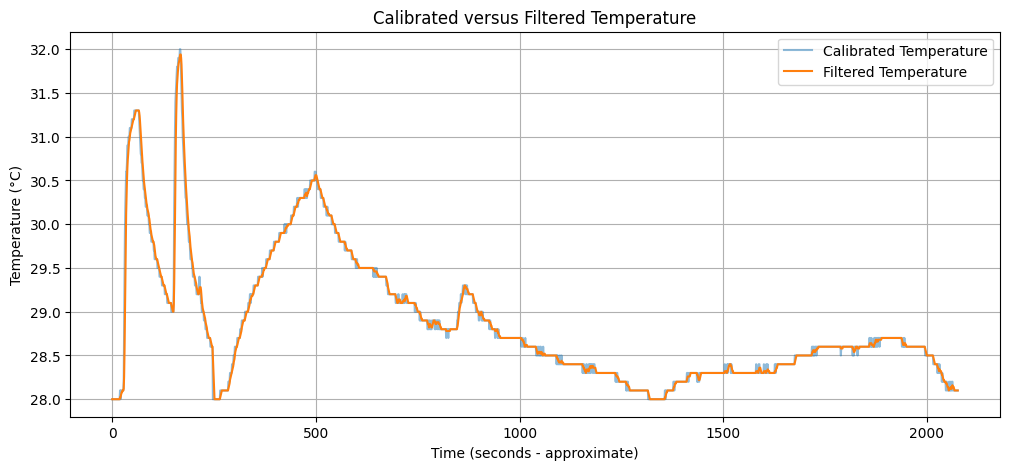

In [28]:
# GRAPH 4: Calibrated versus Filtered Temperature

plt.figure(figsize=(12, 5))

plt.plot(
    df['Elapsed_Time_Seconds'],
    df['Calibrated_Temperature_C'],
    label='Calibrated Temperature',
    alpha=0.5
)

plt.plot(
    df['Elapsed_Time_Seconds'],
    df['Filtered_Temperature_C'],
    label='Filtered Temperature'
)

plt.xlabel('Time (seconds - approximate)')
plt.ylabel('Temperature (°C)')
plt.title('Calibrated versus Filtered Temperature')

plt.legend()
plt.grid(True)


plt.show()

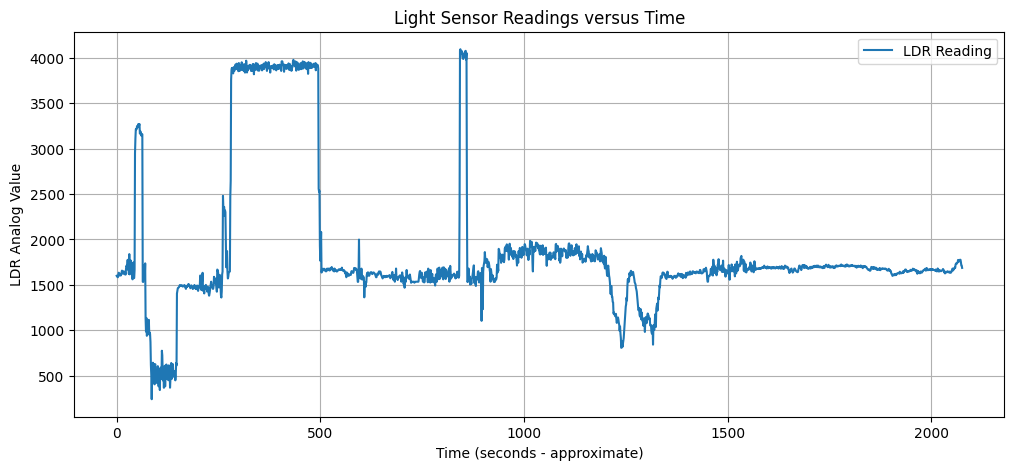

In [29]:
# GRAPH 5: Light Intensity versus Time

plt.figure(figsize=(12, 5))

plt.plot(
    df['Elapsed_Time_Seconds'],
    df['LDR_Analog_Value'],
    label='LDR Reading'
)

plt.xlabel('Time (seconds - approximate)')
plt.ylabel('LDR Analog Value')
plt.title('Light Sensor Readings versus Time')

plt.legend()
plt.grid(True)


plt.show()

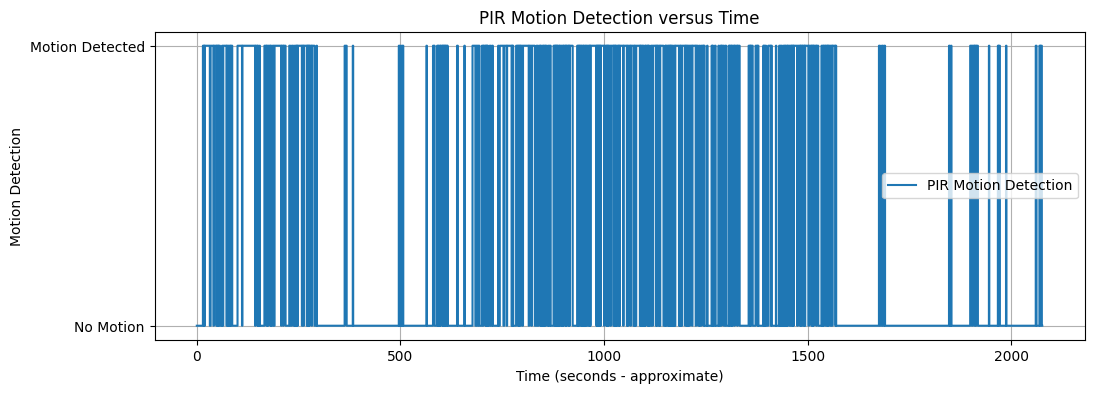

In [30]:
# GRAPH 6: Motion Detection versus Time

plt.figure(figsize=(12, 4))

plt.step(
    df['Elapsed_Time_Seconds'],
    df['Motion_Detected'],
    where='post',
    label='PIR Motion Detection'
)

plt.xlabel('Time (seconds - approximate)')
plt.ylabel('Motion Detection')
plt.title('PIR Motion Detection versus Time')

plt.yticks([0, 1], ['No Motion', 'Motion Detected'])

plt.legend()
plt.grid(True)


plt.show()

In [32]:
# STEP 16: Create processed dataset

processed_df = df.copy()

processed_df = processed_df[
    [
        'Sample_Number',
        'Elapsed_Time_Seconds',
        'Raw_Temperature_C',
        'Calibrated_Temperature_C',
        'Filtered_Temperature_C',
        'Temperature_Rate_of_Change',
        'Humidity_Percent',
        'LDR_Analog_Value',
        'Motion_Detected',

    ]
]

print("Processed dataset created!")

display(processed_df.head())

Processed dataset created!


,Sample_Number,Elapsed_Time_Seconds,Raw_Temperature_C,Calibrated_Temperature_C,Filtered_Temperature_C,Temperature_Rate_of_Change,Humidity_Percent,LDR_Analog_Value,Motion_Detected
0,1,0,31.1,28.0,28.0,NaN,49.9,1600,0
1,2,1,31.1,28.0,28.0,0.0,50.0,1591,0
2,3,2,31.1,28.0,28.0,0.0,50.0,1589,0
3,4,3,31.1,28.0,28.0,0.0,50.1,1584,0
4,5,4,31.1,28.0,28.0,0.0,50.1,1607,0


In [33]:
# STEP 17: Save processed dataset as CSV

processed_df.to_csv(
    'ESP32_Processed_Data.csv',
    index=False
)

print("Processed dataset saved successfully!")

Processed dataset saved successfully!


In [34]:
# STEP 18: Save descriptive statistics

statistics.to_csv(
    'ESP32_Descriptive_Statistics.csv'
)

print("Descriptive statistics exported!")

Descriptive statistics exported!


In [38]:
# STEP 20: Create final results folder

os.makedirs('ESP32_Lab1_Results', exist_ok=True)


# Copy processed dataset
shutil.copy(
    'ESP32_Processed_Data.csv',
    'ESP32_Lab1_Results/ESP32_Processed_Data.csv'
)

# Copy descriptive statistics
shutil.copy(
    'ESP32_Descriptive_Statistics.csv',
    'ESP32_Lab1_Results/ESP32_Descriptive_Statistics.csv'
)


print("All results organised successfully!")

All results organised successfully!


In [39]:
# STEP 21: Compress all results into ZIP

shutil.make_archive(
    'ESP32_Lab1_Results',
    'zip',
    'ESP32_Lab1_Results'
)

# Download ZIP folder
files.download('ESP32_Lab1_Results.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>